In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('/content/housing[1].csv')

In [3]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [5]:
df.shape

(20640, 10)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


In [8]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [9]:
print(df['median_house_value'].describe())

count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64


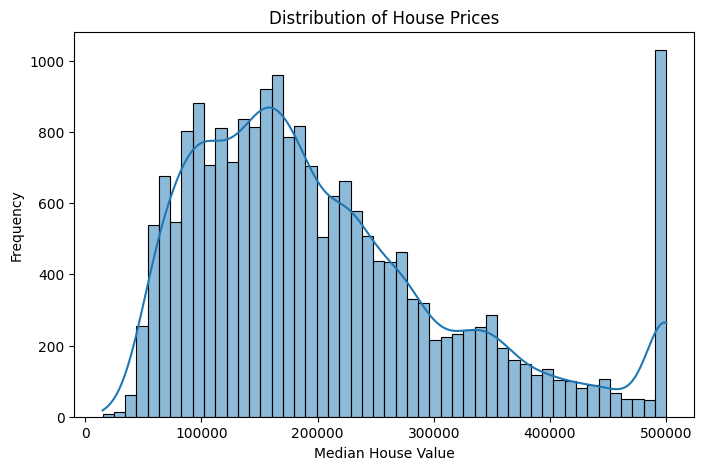

In [10]:
plt.figure(figsize=(8,5))
sns.histplot(df['median_house_value'], bins=50, kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")
plt.show()

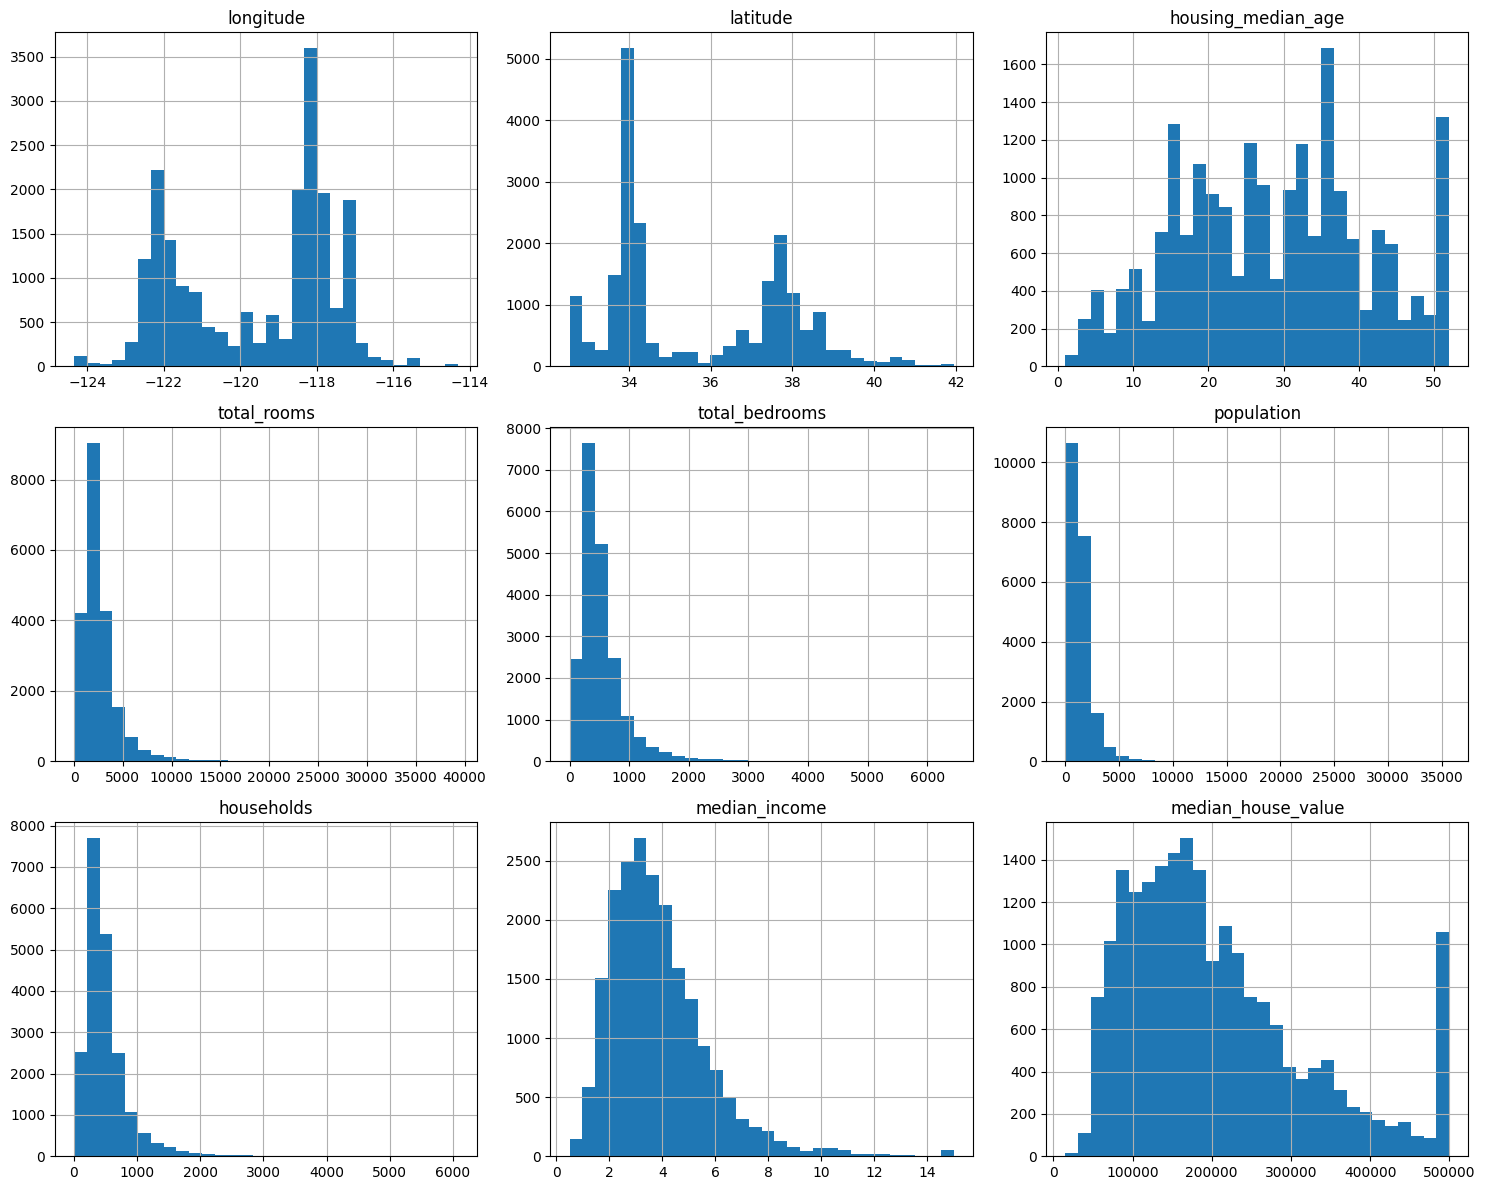

In [11]:
df.hist(figsize=(15,12), bins=30)
plt.tight_layout()
plt.show()

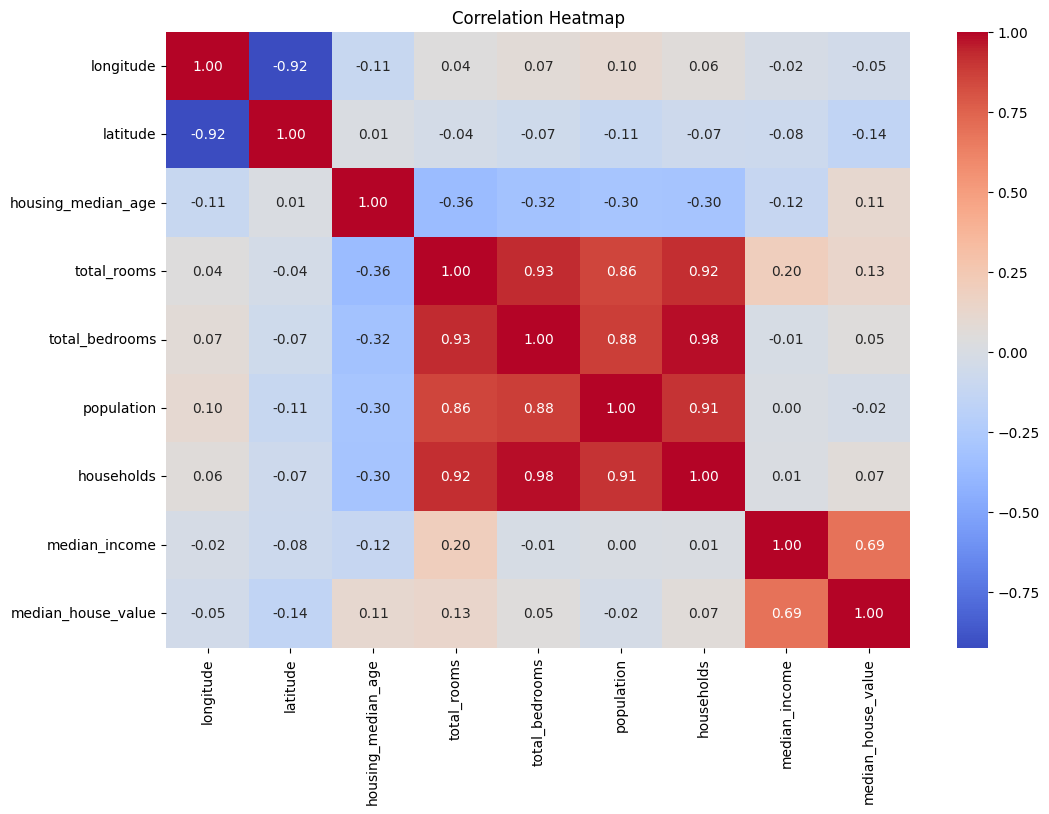

In [12]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(12,8))
sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

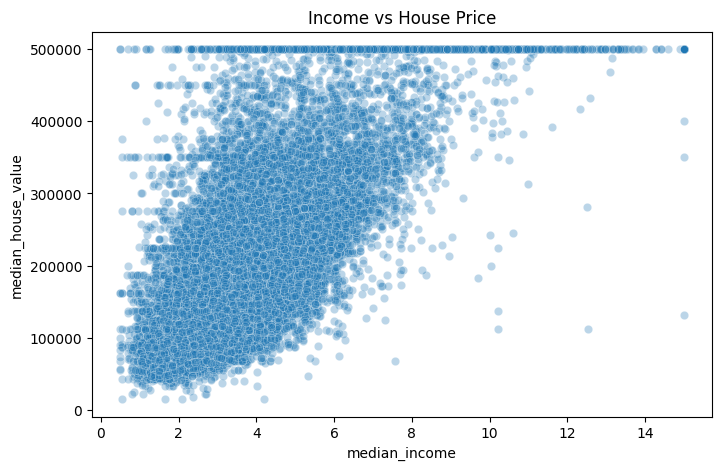

In [13]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df,x='median_income',y='median_house_value',alpha=0.3)

plt.title("Income vs House Price")
plt.show()

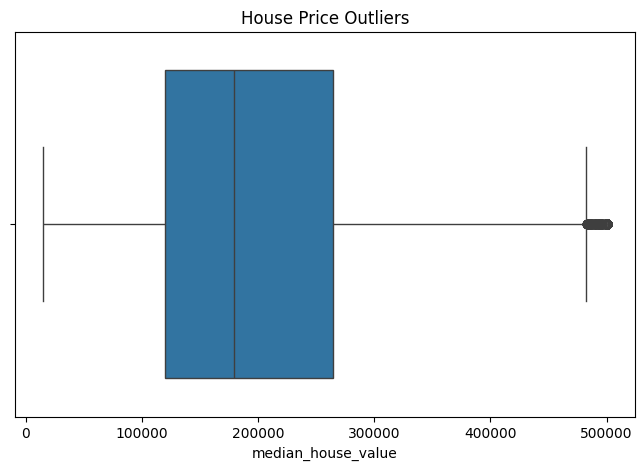

In [14]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['median_house_value'])
plt.title("House Price Outliers")
plt.show()

In [15]:
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

In [16]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 9)
Target shape: (20640,)


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 9)
X_test: (4128, 9)
y_train: (16512,)
y_test: (4128,)


In [19]:
num_col = X_train.select_dtypes(
    include=['int64', 'float64']
).columns

cat_col = X_train.select_dtypes(
    include=['object']
).columns

print("Numerical columns:", num_col)
print("Categorical columns:", cat_col)

Numerical columns: Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income'],
      dtype='object')
Categorical columns: Index(['ocean_proximity'], dtype='object')


In [20]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')
X_train[num_col] = imputer.fit_transform(X_train[num_col])

In [21]:
X_test[num_col] = imputer.transform(X_test[num_col])

In [22]:
print("Training missing values:")
print(X_train[num_col].isnull().sum())

print("Testing missing values:")
print(X_test[num_col].isnull().sum())

Training missing values:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
dtype: int64
Testing missing values:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
dtype: int64


In [23]:
print(cat_col)
print(X_train[cat_col].head())

Index(['ocean_proximity'], dtype='object')
      ocean_proximity
14196      NEAR OCEAN
8267       NEAR OCEAN
17445      NEAR OCEAN
14265      NEAR OCEAN
2271           INLAND


In [24]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown='ignore',sparse_output=False)
X_train_encoded = encoder.fit_transform(X_train[cat_col])
X_test_encoded = encoder.transform(X_test[cat_col])

In [25]:
print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

print("Categories:", encoder.categories_)

Encoded training shape: (16512, 5)
Encoded testing shape: (4128, 5)
Categories: [array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]


In [26]:
X_train_final = np.concatenate([X_train[num_col].to_numpy(), X_train_encoded],axis=1)

X_test_final = np.concatenate([X_test[num_col].to_numpy(), X_test_encoded],axis=1)

In [27]:
print(X_train_final.shape)
print(X_test_final.shape)

(16512, 13)
(4128, 13)


In [28]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1)

In [29]:
model.fit(X_train_final, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [30]:
y_pred = model.predict(X_test_final)

In [31]:
comparison = pd.DataFrame({'Actual Price': y_test.values,'Predicted Price': y_pred})

print(comparison.head(10))

   Actual Price  Predicted Price
0       47700.0         51744.00
1       45800.0         71115.00
2      500001.0        461228.37
3      218600.0        255273.00
4      278000.0        268203.00
5      158700.0        162987.00
6      198200.0        226729.02
7      157500.0        168559.00
8      340000.0        289892.05
9      446600.0        484186.71


In [32]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 31636.34963905039
MSE: 2398752750.885072
RMSE: 48977.063518396775
R2 Score: 0.8169462518407672


In [33]:
importance = model.feature_importances_

feature_names = list(num_col) + list(encoder.get_feature_names_out(cat_col))

feature_importance = pd.DataFrame({'Feature': feature_names,'Importance': importance})

feature_importance = feature_importance.sort_values(by='Importance',ascending=False)

print(feature_importance)

                       Feature  Importance
7                median_income    0.490642
9       ocean_proximity_INLAND    0.140925
0                    longitude    0.105889
1                     latitude    0.101597
2           housing_median_age    0.051935
5                   population    0.032573
4               total_bedrooms    0.023819
3                  total_rooms    0.023366
6                   households    0.018367
12  ocean_proximity_NEAR OCEAN    0.006336
8    ocean_proximity_<1H OCEAN    0.003386
11    ocean_proximity_NEAR BAY    0.000711
10      ocean_proximity_ISLAND    0.000455


In [34]:
param_grid = {'n_estimators': [100, 200],'max_depth': [10, 20]}

In [35]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 15, 20],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_final, y_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


GridSearchCV(cv=3, estimator=RandomForestRegressor(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [None, 15, 20],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='r2', verbose=1)

In [36]:
print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV R2 Score:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best CV R2 Score:
0.8133487563266838


In [37]:
# Get the best model
best_model = grid_search.best_estimator_

# Predict using the test data
y_pred_tuned = best_model.predict(X_test_final)

# Evaluate tuned model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_tuned = mean_absolute_error(y_test, y_pred_tuned)
mse_tuned = mean_squared_error(y_test, y_pred_tuned)
rmse_tuned = np.sqrt(mse_tuned)
r2_tuned = r2_score(y_test, y_pred_tuned)

print("Tuned Model Results")
print("MAE:", mae_tuned)
print("MSE:", mse_tuned)
print("RMSE:", rmse_tuned)
print("R2 Score:", r2_tuned)

Tuned Model Results
MAE: 31486.801327519377
MSE: 2383729507.6286907
RMSE: 48823.452434549225
R2 Score: 0.818092706383268
